# Hyperparameters in Deep Learning — a hands-on tour with PyTorch Lightning

This notebook builds a small but complete image-classification framework on **Fashion-MNIST** and uses it to study **hyperparameters**: what they are, where they live in the code, and what happens when you change them.

**What you will build**

1. One `HParams` config object that holds *every* hyperparameter in one place
2. A `LightningDataModule` (data), a CNN (`nn.Module`) and a `LightningModule` (training logic)
3. A `fit()` helper that trains a model from a config and returns its learning curves
4. Controlled experiments: learning rate, batch size, optimizer, regularisation
5. A small random search, then one final evaluation on the test set

**Parameters vs. hyperparameters**

| | Parameters | Hyperparameters |
|---|---|---|
| What | Weights and biases of the network | Settings that define the model and how it is trained |
| Who sets them | The optimizer, by gradient descent | You, before training starts |
| Learned from | Training data | Validation performance (trial and comparison) |
| Examples | Conv kernels, linear weights | Learning rate, batch size, dropout, number of layers |

A useful mental model: the optimizer searches for good **parameters** inside a search problem that the **hyperparameters** define. Bad hyperparameters make that inner problem hard or impossible, no matter how long you train.

## 0. Setup

Uncomment the next cell if the packages are not installed yet (for example on a fresh Colab runtime).

In [1]:
%pip install torch torchvision lightning pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 25.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 52.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 22.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [lightning]


In [2]:
import logging
import random
import time
import warnings
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Lightning 2.x is imported as `lightning`; older installs use `pytorch_lightning`.
try:
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    _LIGHTNING_LOGGER = "lightning.pytorch"
except ImportError:
    import pytorch_lightning as L
    from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
    from pytorch_lightning.loggers import CSVLogger
    _LIGHTNING_LOGGER = "pytorch_lightning"

# Keep the output readable during the many short training runs below.
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*logging interval.*")

print("torch:", torch.__version__)
print("lightning:", L.__version__)
print("GPU available:", torch.cuda.is_available())

torch: 2.14.1+cu130
lightning: 2.6.6
GPU available: True


## 1. All hyperparameters in one place

The single most useful habit when working with hyperparameters is to **keep them out of the code body**. Nothing below this cell contains a hard-coded `0.001` or `64`; every tunable number is a field of `HParams`.

This gives you three things for free:

- **Reproducibility** — a run is fully described by one small object
- **Easy experiments** — `replace(hp, lr=0.01)` creates a variant without touching the model
- **Logging** — Lightning stores the config next to the metrics and inside every checkpoint

The fields fall into four families:

| Family | Fields | What they control |
|---|---|---|
| **Data** | `batch_size`, `val_fraction`, `train_subset`, `augment` | What the model sees in each step |
| **Model (architecture)** | `conv1_channels`, `conv2_channels`, `hidden_dim`, `activation`, `use_batchnorm`, `dropout` | Capacity: how complex a function the network can represent |
| **Optimisation** | `optimizer`, `lr`, `momentum`, `weight_decay`, `scheduler` | How the weights move at each step |
| **Training loop** | `max_epochs`, `patience`, `seed` | How long training runs and where it starts from |

In [3]:
@dataclass
class HParams:
    # ---- Data -------------------------------------------------------------
    data_dir: str = "./data"
    batch_size: int = 64          # samples per gradient step
    val_fraction: float = 0.1     # share of the training set held out for validation
    train_subset: Optional[int] = None  # use only N training images (None = all); for fast experiments
    augment: bool = False         # random crop + horizontal flip on training images
    num_workers: int = 0          # data-loading processes (not a model hyperparameter; 0 is safest in notebooks)

    # ---- Model ------------------------------------------------------------
    conv1_channels: int = 32      # width of the first conv block
    conv2_channels: int = 64      # width of the second conv block
    hidden_dim: int = 128         # size of the fully connected layer
    activation: str = "relu"      # relu | leaky_relu | gelu | tanh
    use_batchnorm: bool = True    # batch normalisation after each conv
    dropout: float = 0.25         # probability of zeroing an activation in the classifier head

    # ---- Optimisation -----------------------------------------------------
    optimizer: str = "adam"       # sgd | adam | adamw
    lr: float = 1e-3              # learning rate (step size)
    momentum: float = 0.9         # used by SGD only
    weight_decay: float = 0.0     # L2-style penalty on the weights
    scheduler: str = "none"       # none | step | cosine

    # ---- Training loop ----------------------------------------------------
    max_epochs: int = 5           # upper limit on passes over the training set
    patience: int = 3             # early stopping: epochs without val_loss improvement before stopping
    seed: int = 42                # controls weight init, data split and shuffling


hp = HParams()
pd.Series(asdict(hp), name="value").to_frame()

,value
data_dir,./data
batch_size,64
val_fraction,0.1
train_subset,None
augment,False
num_workers,0
conv1_channels,32
conv2_channels,64
hidden_dim,128
activation,relu


## 2. Data: Fashion-MNIST in a `LightningDataModule`

Fashion-MNIST ships with `torchvision.datasets`: 60,000 training and 10,000 test images, 28×28 grayscale, 10 clothing classes. It is as small as MNIST but hard enough that hyperparameter choices visibly matter.

**Three splits, three jobs**

- **Train** — used to fit the *parameters*
- **Validation** — used to choose the *hyperparameters* (and for early stopping)
- **Test** — used **once**, at the very end, to report the final number

If you tune hyperparameters on the test set, the test score stops being an honest estimate of how the model performs on new data. That is why `val_fraction` exists.

**Hyperparameters used here**

- `batch_size` — how many images make up one gradient estimate
- `val_fraction` — bigger means a more reliable validation score but less training data
- `augment` — random transformations that make the training set effectively larger (a form of regularisation)
- `train_subset` — not something you would tune for a final model, but very handy for cheap experiments

In [4]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Mean and standard deviation of the Fashion-MNIST training pixels.
FMNIST_MEAN, FMNIST_STD = (0.2860,), (0.3530,)


class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        normalize = transforms.Normalize(FMNIST_MEAN, FMNIST_STD)
        self.eval_transform = transforms.Compose([transforms.ToTensor(), normalize])

        augmentations = []
        if hp.augment:  # <-- hyperparameter: augment
            augmentations = [transforms.RandomCrop(28, padding=2),
                             transforms.RandomHorizontalFlip()]
        self.train_transform = transforms.Compose([*augmentations, transforms.ToTensor(), normalize])

    def prepare_data(self):
        # Download once. Lightning calls this on a single process.
        datasets.FashionMNIST(self.hp.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        # Two views of the same 60k images: one with training transforms, one without.
        train_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.train_transform)
        eval_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.eval_transform)

        n_total = len(train_view)
        n_val = int(n_total * self.hp.val_fraction)  # <-- hyperparameter: val_fraction
        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(n_total, generator=generator).tolist()
        val_idx, train_idx = indices[:n_val], indices[n_val:]

        if self.hp.train_subset is not None:  # <-- hyperparameter: train_subset
            train_idx = train_idx[: self.hp.train_subset]

        self.train_ds = Subset(train_view, train_idx)
        self.val_ds = Subset(eval_view, val_idx)
        self.test_ds = datasets.FashionMNIST(self.hp.data_dir, train=False, transform=self.eval_transform)

    def _loader(self, dataset, batch_size, shuffle):
        return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                          num_workers=self.hp.num_workers,
                          persistent_workers=self.hp.num_workers > 0)

    def train_dataloader(self):
        return self._loader(self.train_ds, self.hp.batch_size, shuffle=True)  # <-- hyperparameter: batch_size

    def val_dataloader(self):
        # The evaluation batch size only affects speed, never the result.
        return self._loader(self.val_ds, 512, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_ds, 512, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.84MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.3MB/s]


train: 54,000   val: 6,000   test: 10,000
batch shape: (512, 1, 28, 28)


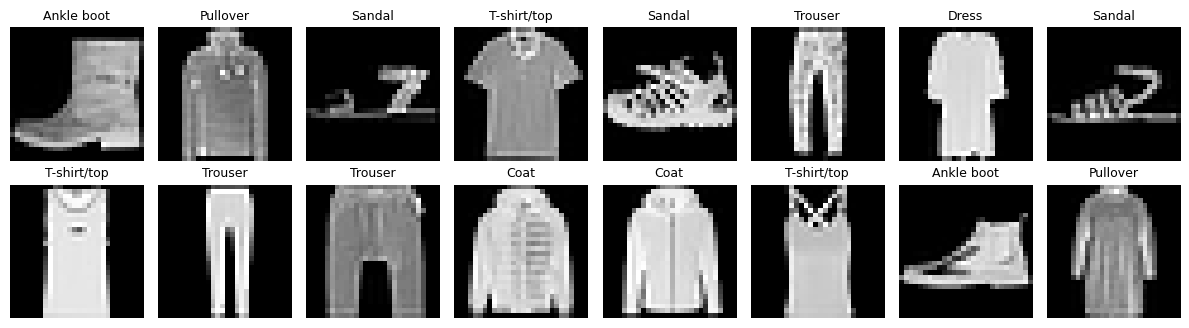

In [5]:
dm = FashionMNISTDataModule(hp)
dm.prepare_data()
dm.setup()
print(f"train: {len(dm.train_ds):,}   val: {len(dm.val_ds):,}   test: {len(dm.test_ds):,}")

images, labels = next(iter(dm.val_dataloader()))
print("batch shape:", tuple(images.shape))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, label in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze() * FMNIST_STD[0] + FMNIST_MEAN[0], cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Model: architecture hyperparameters

The network is a classic small CNN:

```
input 1×28×28
 → Conv(3×3, conv1_channels) → [BatchNorm] → activation → MaxPool   (14×14)
 → Conv(3×3, conv2_channels) → [BatchNorm] → activation → MaxPool   (7×7)
 → Flatten → Dropout → Linear(hidden_dim) → activation → Dropout → Linear(10)
```

Every architectural choice is read from `HParams`:

- **Width** (`conv1_channels`, `conv2_channels`, `hidden_dim`) sets the **capacity** of the model. More capacity can fit more complex patterns, but costs compute and overfits more easily.
- **`activation`** is the non-linearity. ReLU is the default workhorse; GELU and LeakyReLU are common alternatives; tanh saturates and usually trains more slowly in deep networks.
- **`use_batchnorm`** normalises activations within each batch. It tends to make training faster and much less sensitive to the learning rate.
- **`dropout`** randomly zeroes activations during training, which discourages the network from relying on any single feature. It is a regulariser: it lowers training accuracy on purpose in exchange for better generalisation.

Depth (the number of layers) is also a hyperparameter. It is fixed at two conv blocks here to keep the notebook short; see the exercises at the end.

In [6]:
ACTIVATIONS = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU, "tanh": nn.Tanh}


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act = ACTIVATIONS[hp.activation]            # <-- hyperparameter: activation
        c1, c2 = hp.conv1_channels, hp.conv2_channels  # <-- hyperparameters: width

        def conv_block(in_ch, out_ch):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
            if hp.use_batchnorm:                    # <-- hyperparameter: use_batchnorm
                layers.append(nn.BatchNorm2d(out_ch))
            layers += [act(), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(conv_block(1, c1), conv_block(c1, c2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),                 # <-- hyperparameter: dropout
            nn.Linear(c2 * 7 * 7, hp.hidden_dim),   # <-- hyperparameter: hidden_dim
            act(),
            nn.Dropout(hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


model = SmallCNN(hp)
print(model)
print(f"\ntrainable parameters: {count_parameters(model):,}")

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

trainable parameters: 421,834


Architecture hyperparameters change the **number of parameters**, and you can see that without training anything:

In [7]:
variants = {
    "tiny   (8, 16, 32)": dict(conv1_channels=8, conv2_channels=16, hidden_dim=32),
    "small  (16, 32, 64)": dict(conv1_channels=16, conv2_channels=32, hidden_dim=64),
    "default (32, 64, 128)": dict(),
    "wide   (64, 128, 256)": dict(conv1_channels=64, conv2_channels=128, hidden_dim=256),
}
pd.DataFrame(
    {"trainable parameters": {name: count_parameters(SmallCNN(replace(hp, **overrides)))
                              for name, overrides in variants.items()}}
)

,trainable parameters
"tiny (8, 16, 32)",26746
"small (16, 32, 64)",105962
"default (32, 64, 128)",421834
"wide (64, 128, 256)",1683338


## 4. Training logic: the `LightningModule`

A `LightningModule` wraps the network and answers three questions:

1. **What is one training step?** → `training_step`
2. **How do we evaluate?** → `validation_step`, `test_step`
3. **How do the weights get updated?** → `configure_optimizers`

`configure_optimizers` is where the **optimisation hyperparameters** live.

### Learning rate

Plain gradient descent updates the weights $\theta$ with

$$\theta \leftarrow \theta - \eta \,\nabla_\theta \mathcal{L}(\theta)$$

where $\eta$ is the **learning rate**. It is usually the most important hyperparameter:

- **too small** → training crawls and may stop far from a good solution within your epoch budget
- **too large** → the loss oscillates or blows up
- **about right** → the loss drops quickly and settles

### Optimizer

- **SGD** uses the raw gradient. With **`momentum`** it keeps a running average of past gradients, which smooths the path and speeds things up along consistent directions.
- **Adam** adapts the step size per parameter. It usually works well out of the box with `lr ≈ 1e-3`.
- **AdamW** is Adam with weight decay applied correctly (decoupled from the adaptive step). Prefer it over Adam whenever `weight_decay > 0`.

Good learning rates are **not transferable between optimizers**: `0.1` can be fine for SGD and disastrous for Adam.

### Weight decay

Shrinks the weights a little at every step, which is equivalent in spirit to adding $\lambda \lVert\theta\rVert^2$ to the loss. It pushes the model towards simpler solutions (regularisation).

### Learning-rate scheduler

Changes $\eta$ during training. A common pattern is to start with larger steps to make fast progress and finish with smaller steps to settle. `step` divides the rate by 10 at fixed intervals; `cosine` lowers it smoothly to zero.

The call to `save_hyperparameters` stores the config in `self.hparams`, in the logger output (`hparams.yaml`) and inside every checkpoint.

In [8]:
class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))  # logged + stored in checkpoints
        self.model = SmallCNN(hp)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch, stage: str):
        x, y = batch
        logits = self(x)
        loss = self.loss_fn(logits, y)
        acc = (logits.argmax(dim=1) == y).float().mean()
        # on_epoch=True: Lightning averages over the epoch (weighted by batch size).
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log(f"{stage}_acc", acc, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._shared_step(batch, "test")

    def configure_optimizers(self):
        hp = self.hp
        params = self.parameters()

        # <-- hyperparameters: optimizer, lr, momentum, weight_decay
        if hp.optimizer == "sgd":
            optimizer = torch.optim.SGD(params, lr=hp.lr, momentum=hp.momentum, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adam":
            optimizer = torch.optim.Adam(params, lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adamw":
            optimizer = torch.optim.AdamW(params, lr=hp.lr, weight_decay=hp.weight_decay)
        else:
            raise ValueError(f"unknown optimizer: {hp.optimizer}")

        # <-- hyperparameter: scheduler
        if hp.scheduler == "none":
            return optimizer
        if hp.scheduler == "step":
            scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, hp.max_epochs // 3), gamma=0.1)
        elif hp.scheduler == "cosine":
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=hp.max_epochs)
        else:
            raise ValueError(f"unknown scheduler: {hp.scheduler}")
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}

## 5. The training loop: `Trainer` hyperparameters

Lightning's `Trainer` replaces the hand-written loop (`for epoch ... for batch ... loss.backward() ...`). The hyperparameters that belong to the loop itself are:

- **`max_epochs`** — one epoch is one full pass over the training set. Too few and the model **underfits**; too many and it may **overfit** (and you waste compute).
- **`patience`** (early stopping) — stop when `val_loss` has not improved for this many epochs. This turns "how many epochs?" from a guess into something the validation set decides. `max_epochs` then acts as an upper limit.
- **`seed`** — fixes the random weight initialisation, the data split and the shuffling order. Two runs with different seeds give slightly different results, so small differences between hyperparameter settings may just be noise.

The `fit()` helper below is the whole "framework": config in, trained model and learning curves out. Everything after this section is just calling it with different configs.

In [9]:
def load_history(log_dir) -> pd.DataFrame:
    """Read Lightning's metrics.csv and return one row per epoch."""
    df = pd.read_csv(Path(log_dir) / "metrics.csv")
    cols = [c for c in ["train_loss", "val_loss", "train_acc", "val_acc"] if c in df.columns]
    return df.groupby("epoch")[cols].mean().reset_index()


def fit(hp: HParams, run_name: str = "run", verbose: bool = True, checkpoint: bool = False):
    """Train one model from a config. Returns (trainer, model, datamodule, history)."""
    for name in (_LIGHTNING_LOGGER, "lightning.fabric", "lightning_fabric"):
        logging.getLogger(name).setLevel(logging.INFO if verbose else logging.ERROR)
    L.seed_everything(hp.seed, workers=True)  # <-- hyperparameter: seed

    datamodule = FashionMNISTDataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger("logs", name=run_name)

    callbacks = [EarlyStopping(monitor="val_loss", mode="min", patience=hp.patience)]  # <-- hyperparameter: patience
    if checkpoint:
        callbacks.append(ModelCheckpoint(monitor="val_acc", mode="max", save_top_k=1))

    trainer = L.Trainer(
        max_epochs=hp.max_epochs,          # <-- hyperparameter: max_epochs
        accelerator="auto",                # GPU if there is one, otherwise CPU
        devices=1,
        logger=logger,
        callbacks=callbacks,
        enable_checkpointing=checkpoint,
        enable_progress_bar=verbose,
        enable_model_summary=verbose,
        log_every_n_steps=10,
    )
    trainer.fit(model, datamodule=datamodule)
    history = load_history(logger.log_dir)
    return trainer, model, datamodule, history

### Baseline run

Start with the defaults. A baseline matters: every later experiment is only meaningful as "better or worse than the baseline".

In [10]:
baseline_hp = HParams()
trainer, model, dm, baseline_history = fit(baseline_hp, run_name="baseline")
baseline_history

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ SmallCNN         │  421 K │ train │     0 │
│ 1 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 421 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 421 K                                                                                                
Total estimated model params size (MB): 1.687                                                                      
Modules in train mode: 20                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.


,epoch,train_loss,val_loss,train_acc,val_acc
0,0,0.442606,0.303086,0.839963,0.886333
1,1,0.314130,0.272184,0.885518,0.898667
2,2,0.271134,0.257511,0.898778,0.908667
3,3,0.249597,0.258150,0.909500,0.904000
4,4,0.233350,0.250200,0.914278,0.909167


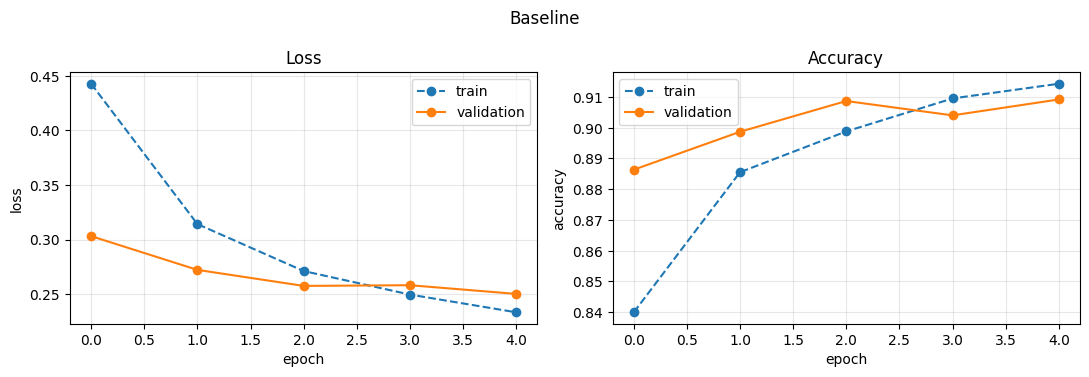

In [11]:
def plot_history(history: pd.DataFrame, title: str = ""):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))
    ax_loss.plot(history["epoch"], history["train_loss"], "o--", label="train")
    ax_loss.plot(history["epoch"], history["val_loss"], "o-", label="validation")
    ax_loss.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax_acc.plot(history["epoch"], history["train_acc"], "o--", label="train")
    ax_acc.plot(history["epoch"], history["val_acc"], "o-", label="validation")
    ax_acc.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
    for ax in (ax_loss, ax_acc):
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(baseline_history, "Baseline")

**How to read learning curves**

| What you see | Diagnosis | Hyperparameters to try |
|---|---|---|
| Train and validation loss both high and still falling | Underfitting / not trained long enough | More epochs, higher `lr`, bigger model |
| Train loss low, validation loss rising | Overfitting | More `dropout`, `weight_decay`, `augment`, smaller model, early stopping |
| Loss jumps around or becomes `nan` | Step size too large | Lower `lr`, add batch norm |
| Loss barely moves from the start | Step size too small (or far too large) | Raise `lr` by 10× and look again |

One detail in this notebook: the training metrics are averaged *during* the epoch, with dropout switched on, while validation runs *after* the epoch with dropout off. So training accuracy can sit a little **below** validation accuracy early on. That is expected, not a bug.

## 6. Experiments: change one thing at a time

To see the effect of one hyperparameter, hold everything else fixed and vary only that one. To keep each run to seconds rather than minutes, the experiments use a **fast config**: 10,000 training images and 4 epochs, with early stopping effectively switched off so every run has the same length.

This is a **proxy**: cheap, and good for seeing *trends*. The best value on a small proxy is not guaranteed to be the best value on the full dataset.

`run_configs` trains one model per entry and collects the learning curves.

In [12]:
FAST = replace(HParams(), train_subset=10_000, max_epochs=4, patience=100)


def run_configs(experiment: str, configs: dict, base: HParams = FAST) -> dict:
    """Train one model per entry of `configs` ({label: {field: value}})."""
    results = {}
    for i, (label, overrides) in enumerate(configs.items()):
        hp_i = replace(base, **overrides)
        start = time.perf_counter()
        _, _, _, history = fit(hp_i, run_name=f"{experiment}/run_{i}", verbose=False)
        seconds = time.perf_counter() - start
        results[label] = {"hp": hp_i, "history": history, "seconds": seconds}
        print(f"{label:<28} best val_acc = {history['val_acc'].max():.4f}   ({seconds:.0f}s)")
    return results


def summarize(results: dict) -> pd.DataFrame:
    rows = []
    for label, r in results.items():
        h = r["history"]
        rows.append({
            "run": label,
            "best_val_acc": h["val_acc"].max(),
            "final_val_loss": h["val_loss"].iloc[-1],
            "final_train_loss": h["train_loss"].iloc[-1],
            "epochs": len(h),
            "seconds": round(r["seconds"], 1),
        })
    return pd.DataFrame(rows).set_index("run")


def plot_runs(results: dict, title: str = "", metrics=("val_loss", "val_acc")):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 3.8))
    for ax, metric in zip(axes, metrics):
        for label, r in results.items():
            ax.plot(r["history"]["epoch"], r["history"][metric], "o-", label=label)
        ax.set(xlabel="epoch", ylabel=metric, title=metric)
        ax.grid(alpha=0.3)
    axes[-1].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 6.1 Learning rate

Learning rates are searched on a **logarithmic scale**: the difference between `0.001` and `0.01` matters far more than the difference between `0.051` and `0.060`. So try powers of ten first, then refine around the best one.

**What to look for:** the smallest rate learns slowly and is still improving when training ends; the largest is unstable or stuck near chance (10% accuracy, loss ≈ 2.3); the best one sits in between.

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.0003                    best val_acc = 0.8710   (16s)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.001                     best val_acc = 0.8758   (17s)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.003                     best val_acc = 0.8775   (16s)


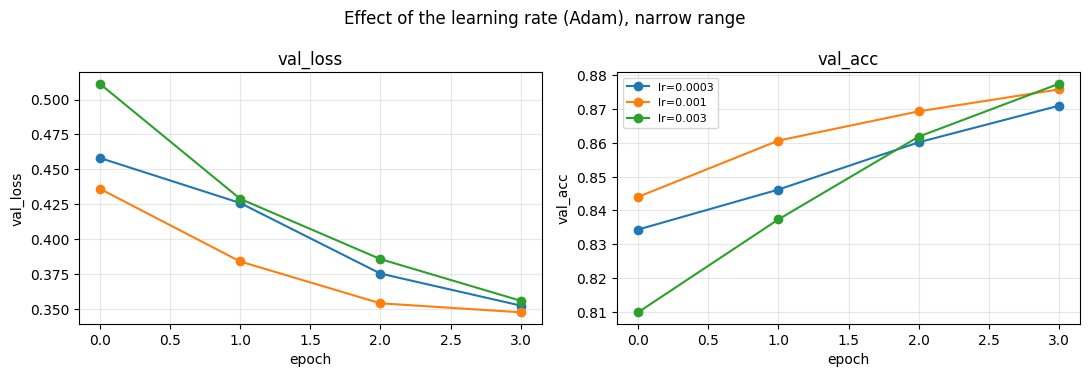

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
lr=0.0003,0.871000,0.352318,0.344188,4,16.4
lr=0.001,0.875833,0.347502,0.329566,4,16.8
lr=0.003,0.877500,0.355785,0.368597,4,16.5


In [13]:
lr_values_narrow = [3e-4, 1e-3, 3e-3]
lr_narrow_results = run_configs("lr_narrow", {f"lr={v:g}": {"lr": v} for v in lr_values_narrow})
plot_runs(lr_narrow_results, "Effect of the learning rate (Adam), narrow range")
summarize(lr_narrow_results)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=1e-05                     best val_acc = 0.7747   (16s)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.0001                    best val_acc = 0.8573   (17s)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.001                     best val_acc = 0.8727   (16s)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.01                      best val_acc = 0.8553   (16s)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.1                       best val_acc = 0.1078   (18s)


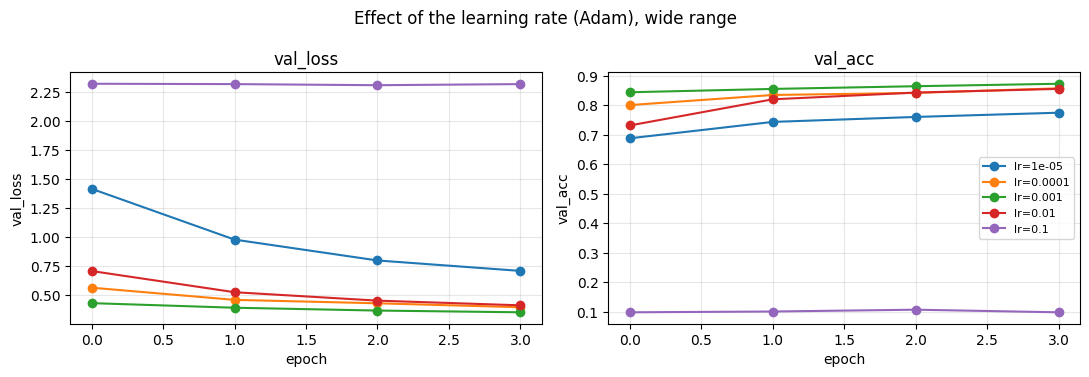

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
lr=1e-05,0.774667,0.706460,0.824246,4,16.3
lr=0.0001,0.857333,0.393686,0.416505,4,16.9
lr=0.001,0.872667,0.349995,0.330636,4,16.4
lr=0.01,0.855333,0.410024,0.517154,4,16.2
lr=0.1,0.107833,2.315130,2.312536,4,17.6


In [14]:
lr_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
lr_wide_results = run_configs("lr_wide", {f"lr={v:g}": {"lr": v} for v in lr_values})
plot_runs(lr_wide_results, "Effect of the learning rate (Adam), wide range")
summarize(lr_wide_results)

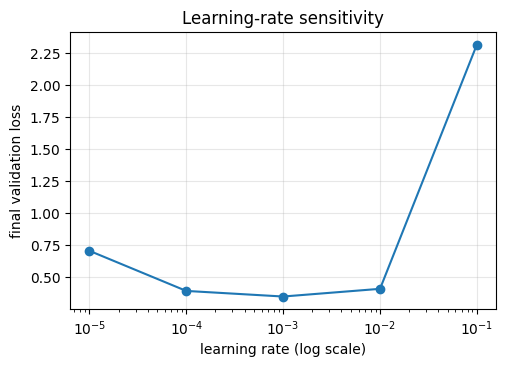

In [15]:
# The classic "U-shape" view: final validation loss against learning rate on a log axis.
final_losses = [lr_wide_results[f"lr={v:g}"]["history"]["val_loss"].iloc[-1] for v in lr_values]
plt.figure(figsize=(5.5, 3.6))
plt.semilogx(lr_values, final_losses, "o-")
plt.xlabel("learning rate (log scale)")
plt.ylabel("final validation loss")
plt.title("Learning-rate sensitivity")
plt.grid(alpha=0.3)
plt.show()

### My changes in 6.1 (what I changed or added)

**Reused from the class notebook (unchanged):** sections 0 to 5, the helper functions `FAST`, `run_configs`, `summarize` and `plot_runs`, and the log-scale learning-rate sensitivity plot.

**What I changed or added:**
- **Added a narrow-range run** (`lr_narrow_results`): lr = 3e-4, 1e-3, 3e-3, to zoom in around the default learning rate.
- **Kept the wide-range run** (lr = 1e-5, 1e-4, 1e-3, 1e-2, 1e-1) from the class notebook, but renamed its results to `lr_wide_results` and its experiment name to `lr_wide` so both runs can be kept and compared.
- **Pointed the sensitivity plot at the wide run** (`lr_results` became `lr_wide_results`).
- **Removed** sections 6.2 to 9 (batch size, optimizer, regularisation, model capacity, random search, final test evaluation and summary), since my post is only about the learning rate.

**Setup (identical for every run):** Fashion-MNIST, small CNN (32 and 64 conv channels, batch norm, 128 hidden units, dropout 0.25), Adam, batch size 64, 4 epochs, seed 42, 10,000 training images (subset), 6,000 validation images. All comparisons use validation results only; the test set is not used.

**Note:** rerunning gives slightly different numbers (about 0.3 percentage points for the same setting), so small differences between runs are within noise.

Base code: class notebook `hyperparameters_lightning.ipynb`.